# **Kurs: 3030.1 - Photogrammetrie**

**Autoren:**  
Jonas Meyer  
Manuela Ammann  
Marianne Deuber  
Prof. Dr. Stephan Nebiker

# **Uebung Funktionales Modell Photogrammetrie**

### Einleitung und Zielsetzung

Bei einer photogrammetrischen Bildaufnahme kann über die Kollinearitätsgleichungen die Beziehung zwischen Bild- und Objektkoordinaten formuliert werden. In dieser Übung wird die Kollinearitätsbeziehung genutzt, um Objektpunktkoordinaten in Bildkoordinaten umzurechnen. Dazu werden die bekannten äusseren und inneren Orientierungen eines Bildes eingelesen, die Bildkoordinaten über die Kollinearitätsgleichung berechnet und die Punkte schliesslich im Bild dargestellt.

Am Schluss dieser Übung solltest du:

* Parameter aus Text-Dateien importieren und in die korrekten Datentypen umwandeln können
* Objektkoordinaten anhand der Kollinearitätsgleichungen in Bildkoordinaten umrechnen können
* Die Umrechnung Objekt- zu Bildkoordinaten verstehen


### Benötigte Module

* numpy
* scikit-image
* matplotlib

### Abgabe

Alle Studierenden müssen ein funktionierendes Code-Repository rechtzeitig auf GitHub (via push-Funktion) abgeben.
Die Funktionstüchtigkeit des eigenen Codes ist sowohl mit Hilfe der vorhandenen unittests sowie anhand der Resultate vorgängig sicherzustellen.

### Vorgehen

Die Übung umfasst die folgenden Schritte:
1.	Importieren der Daten
2.	Parameter der äusseren und inneren Orientierung für weitere Schritte aufbereiten
3.  Berechnung Bildkoordinaten
4.  Darstellung berechneter Bildkoordinaten im Bild

### Zur Info

* Zu ergänzende Code-Stellen sind mit ``#TODO`` gekennnzeichnet.
* Bei Unklarheiten bezüglich der Bedeutung englischer Begriffe aus dem Bereich Photogrammetrie kann [dieses Dokument](https://onlinelibrary.wiley.com/doi/10.1111/phor.12314) konsultiert werden.
* Für die Durchführung der unittests siehe Anleitung in [README.md](README.md).

#### Import notwendiger Module

In [36]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage import io

from src.rotation_matrix import *

## **Schritt 1**

### Datenimport

#### Datenbeschreibung

In dieser Übung stehen zwei verschiedene Bilder aus einer Befliegung mit einer Luftbildkamera Leica RCD30 zur Verfügung. Die Buchstaben N und F identifizieren die Daten der Nadir-Kamera und Forward-Kamera.
Sämtliche Daten sind im Ordner ``data/`` abgelegt.

**Objektpunkte**
* Points_LB.oco

**Nadiraufnahme**
* Innere Orientierung: IO_LB_N.io
* Äussere Orientierung: EO_LB_N.eo
* Luftbild der RCD30 Nadir: 27_031_62056_N.tif

**Forwardaufnahme**
* Innere Orientierung: IO_LB_F.io
* Äussere Orientierung: EO_LB_F.eo
* Luftbild der RCD30 Forward: 27_029_61001_F.tif

#### Definition Dateipfade

Fülle in einem ersten Schritt die Dateipfade in die dafür definierten Variabeln ab.

In [37]:
path_eo_file = #TODO
path_io_file = #TODO
path_object_points = #TODO
path_img = #TODO

#### Laden der Wert

Lade die Daten aus den zuvor definierten Dateipfade. Beachte dabei, dass die erste Zeile jeweils den Header enthält und das Trennzeichen ein `;` ist.
Für die korrekte Nutzung der Funktion [np.loadtxt](https://numpy.org/doc/stable/reference/generated/numpy.loadtxt.html) nutze die entsprechende Dokumentation.

In [38]:
exterior_ori = np.loadtxt(#TODO)
interior_ori = #TODO
object_points = #TODO
img = #TODO

Stelle das zuvor geladene Bild dar (Hinweis: nutze dazu [diese Funktion](https://scikit-image.org/docs/stable/api/skimage.io.html#skimage.io.imshow)). Welche weiteren Funktionen gäbe es für die Darstellung von Bilddaten?

In [ ]:
#TODO

## **Schritt 2**

### Parameter für weitere Schritte aufbereiten

#### Äussere Orientierung der Bildaufnahme

Lese die Position des Projektionszentrums aus der Variable ``exterior_ori`` und weise die Koordinaten den Variablen  ``X0``, ``Y0`` und ``Z0`` zu. Für die Wahl der korrekten Indices kannst du den Header der Originaldatei im ``data`` Ordner konsultieren.

In [39]:
X0, Y0, Z0 = #TODO

Lese ebenfalls die Eulerwinkel aus der Variable  ``exterior_ori`` aus, wandle diese von Grad in Radiant um und weise sie den Variablen  ``omega``, ``phi`` und ``kappa`` zu.

In [40]:
omega, phi, kappa = #TODO

Ergänze in der Funktion ``calculate_rotation_matrix`` in der Datei [src/rotation_matrix.py](src/rotation_matrix.py) die Berechnung der Elemente (`r22`,`r33`) der Rotationsmatrix gemäss der folgenden Fromel.

$$R=\begin{bmatrix}
    \cos \varphi \cos \kappa& -\cos \varphi\ \sin\kappa& \sin \varphi \\
    \cos \omega \sin \kappa + \sin\omega \sin \varphi\ \cos \kappa & \cos \omega \cos \kappa - \sin \omega \sin \varphi \sin \kappa & - \sin \omega \cos \varphi \\
    \sin \omega \sin \kappa - \cos \omega \sin \varphi \cos \kappa & \sin \omega \cos \kappa + \cos \omega \sin \varphi \sin \kappa & \cos \omega \cos \varphi
\end{bmatrix}$$

In [41]:
R = calculate_rotation_matrix(omega, phi, kappa)

r11 = R[0,0]
r12 = R[0,1]
r13 = R[0,2]
r21 = #TODO
r22 = R[1,1]
r23 = R[1,2]
r31 = R[2,0]
r32 = R[2,1]
r33 = #TODO

# r11, r12, r13, r21, r22, r23, r31, r32, r33 = R.flatten() # more efficient


#### Innere Orientierung der Bildaufnahme

Lese die Höhe und Breite der Pixel, die Höhe und Breite des Bildes (Einheit: Pixel), sowie die Kamerakonstante und die Position des Bildhauptpunktes in X und Y Richtung aus ``interior_ori`` aus und fülle diese in separate Variablen ab. Nutze dazu wiederum den Header der Originaldatei.


In [42]:
pix_size_x, pix_size_y, size_x, size_y, pd, x0, y0 = #TODO

## **Schritt 3**
### Berechnung Bildkoordinaten

In diesem Schritt werden alle Objektkoordinaten mithilfe einer Schleife in Bildkoordinaten umgewandelt. Zunächst werden die Bildkoordinaten des jeweiligen Objektpuntkes berechnet. Danach wird geprüft, ob die berechneten Bildkoordinaten im gewünschten Bildbereich liegen. Ist dies der Fall, werden die Koordinaten der Liste `image_coords` hinzugefügt. Dieser Vorgang wird für alle Objektpunkte wiederholt.

Erstelle zuerst eine leere Liste für die Variable ``image_coords``. Weise anschliessend innerhalb der Schleife die korrekten Werte den Variablen ``X``, ``Y`` und ``Z`` zu, welche die Objektpunktkoordinaten repräsentieren.

Ergänze anschliessend die Kollinearitätsgleichung für die y-Bildkoordinate gemäss der folgenden Formel. Die Verzeichnungs parameter $dx$ und $dy$ sind in diesem Beispiel Null und können daher ignoriert werden.
$$ x'=x'_0-c_K  \frac{(r_{11} (X-X_0 ) + r_{21} (Y-Y_0 ) + r_{31} (Z-Z_0 ))}{(r_{13} (X-X_0 ) + r_{23} (Y-Y_0 ) + r_{33} (Z-Z_0 ) )}+dx'$$

$$ y'=y'_0-c_K  \frac{(r_{12} (X-X_0 ) + r_{22} (Y-Y_0 ) + r_{32} (Z-Z_0 ))}{(r_{13} (X-X_0 ) + r_{23} (Y-Y_0 ) + r_{33} (Z-Z_0 ) )}+dy'$$


Prüfe zum Schluss ob die Bildkoordinaten innerhalb des Bildes zu liegen kommen.


In [44]:
image_coords = #TODO

for point in object_points:
    point_nr = point[0]
    X, Y, Z = #TODO

    x = #TODO
    y = #TODO

    if #TODO:
        image_coords.append([point_nr,x,y])

Für die automatische Korrektur der Übung, führe bitte die folgende Zelle ohne Anpassungen durch

In [ ]:
result_path = os.path.join(os.path.abspath('.'), "res")

if not os.path.exists(result_path):
    os.makedirs(result_path)

np.save(os.path.join(result_path, "image_coords.npy"), np.array(image_coords))

## **Schritt 4**

### Darstellung berechneter Bildkoordinaten im Bild

Zuletzt werden die berechneten Bildkoordinaten zusammen mit dem Bild visualisiert.

Verändere die Parameter der Plotdarstellung. Erhöhe beisplielsweise die Schriftgrösse oder ändere die Schrift bzw. Markerfarbe. Für das endgültige Resultat und die automatische Korrektur verwende bitte diese Einstellungen:

```python
plt.figure(figsize=(15,10))
plt.imshow(img)

offset = 20

for point in image_coords:
    u = point[1] / pix_size_x + size_x/2
    v = -point[2] / pix_size_y + size_y/2


    plt.scatter(u, v, s=300, c="r", marker="x")
    plt.text(u + offset, v - offset, str(int(point[0])), color="y", fontsize=20, fontweight="normal")

plt.axis('off')
plt.savefig(f"res/result.png", dpi=100, bbox_inches='tight', pad_inches = 0)
```

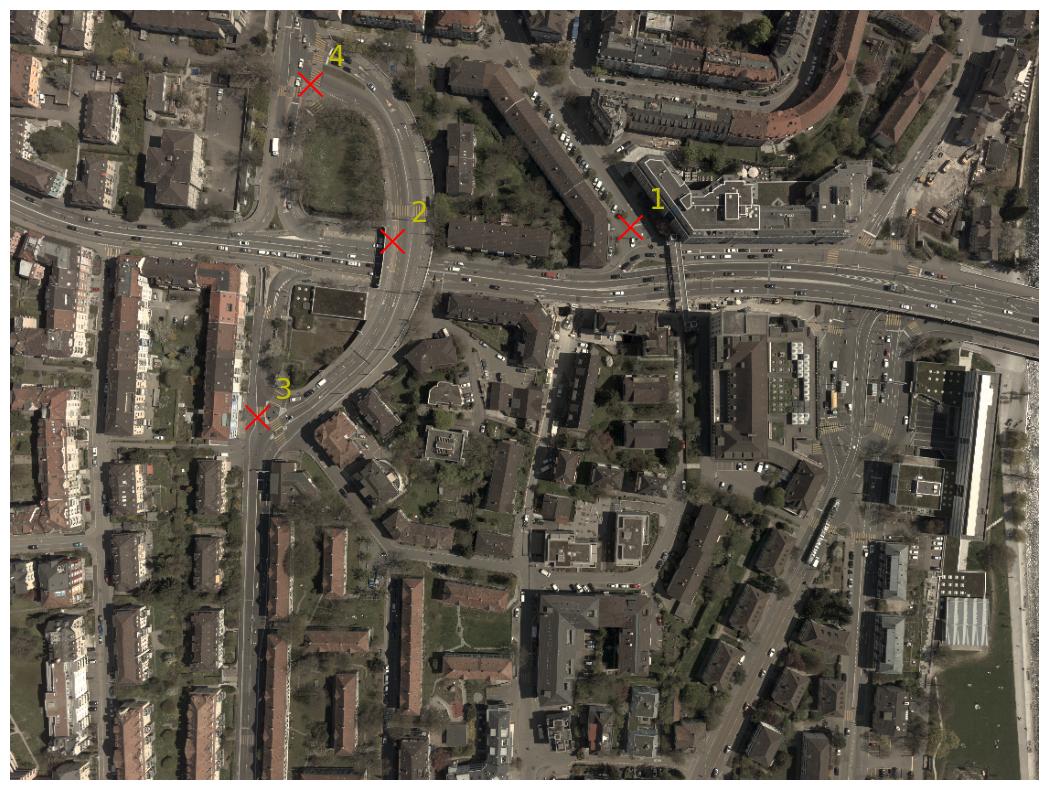

In [45]:
plt.figure(figsize=(15,10))
plt.imshow(img)

offset = 20

for point in image_coords:
    u = point[1] / pix_size_x + size_x/2
    v = -point[2] / pix_size_y + size_y/2


    plt.scatter(u, v, s=300, c="r", marker="x")
    plt.text(u + offset, v - offset, str(int(point[0])), color="y", fontsize=20, fontweight="normal")

plt.axis('off')
plt.savefig(f"res/result.png", dpi=100, bbox_inches='tight', pad_inches = 0)